<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_081_time_series_stationarity.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 81/365 — Stationarity in Time Series
## Why do many forecasting models prefer stable statistical behavior?

Yesterday we learned how to split time-series data correctly.

Today we focus on **Stationarity**.

A stationary series has statistical behavior that is reasonably stable over time.

In simple terms:
- the mean does not keep drifting
- the variance does not keep changing dramatically
- relationships with past values remain reasonably stable


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


## 1. Create a non-stationary time series

In [2]:
rng=np.random.default_rng(42)

dates=pd.date_range(
    start="2026-01-01",
    periods=240,
    freq="D"
)

t=np.arange(len(dates))

trend=100 + 0.35*t
weekly=10*np.sin(2*np.pi*t/7)
noise=rng.normal(0,4,len(dates))

df=pd.DataFrame({
    "date":dates,
    "demand":trend+weekly+noise
})

df.head()


,date,demand
0,2026-01-01,101.218868
1,2026-01-02,104.008378
2,2026-01-03,113.451084
3,2026-01-04,109.151096
4,2026-01-05,89.257022


## 2. Plot the raw series

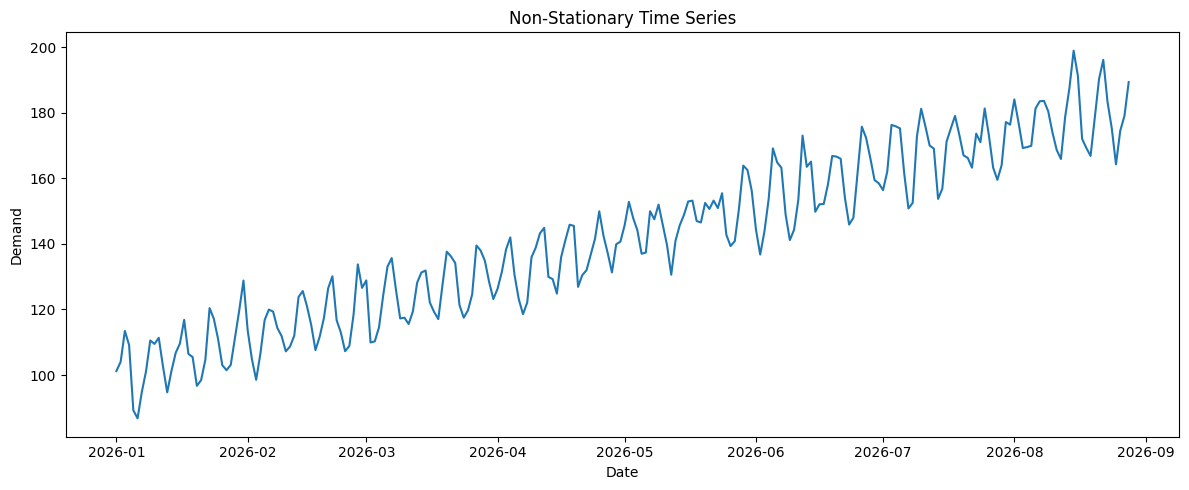

In [3]:
plt.figure(figsize=(12,5))
plt.plot(df["date"],df["demand"])
plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Non-Stationary Time Series")
plt.tight_layout()
plt.show()


## 3. Rolling statistics

A simple visual check is to inspect the rolling mean and rolling standard deviation.

If these keep changing substantially over time, the series may not be stationary.


In [4]:
df["rolling_mean_30"]=df["demand"].rolling(30).mean()
df["rolling_std_30"]=df["demand"].rolling(30).std()


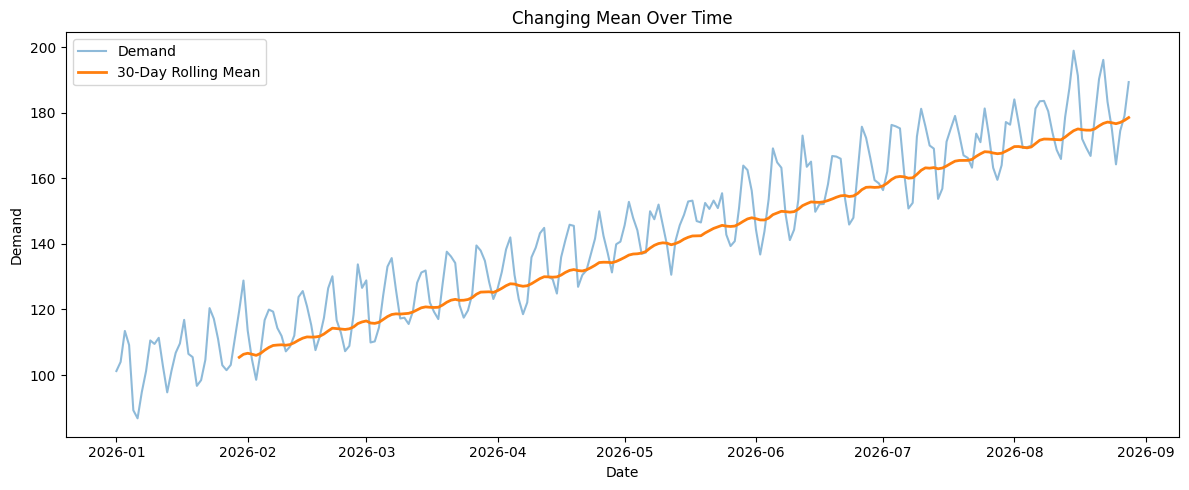

In [5]:
plt.figure(figsize=(12,5))
plt.plot(df["date"],df["demand"],alpha=0.5,label="Demand")
plt.plot(df["date"],df["rolling_mean_30"],linewidth=2,label="30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.title("Changing Mean Over Time")
plt.legend()
plt.tight_layout()
plt.show()


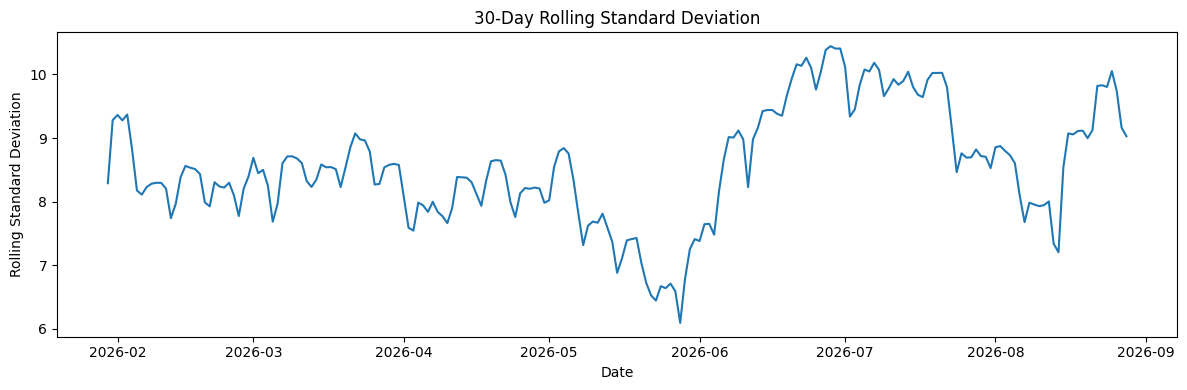

In [6]:
plt.figure(figsize=(12,4))
plt.plot(df["date"],df["rolling_std_30"])
plt.xlabel("Date")
plt.ylabel("Rolling Standard Deviation")
plt.title("30-Day Rolling Standard Deviation")
plt.tight_layout()
plt.show()


## 4. Weak stationarity intuition

A weakly stationary series typically has:

### Stable mean
The average level does not keep drifting.

### Stable variance
The amount of fluctuation remains reasonably consistent.

### Stable autocovariance
The relationship between values separated by the same lag depends mainly on the lag, not on when we measure it.


## 5. First-order differencing

A common way to remove trend is:

`difference_t = value_t - value_(t-1)`

Instead of modeling the absolute level, we model the change.


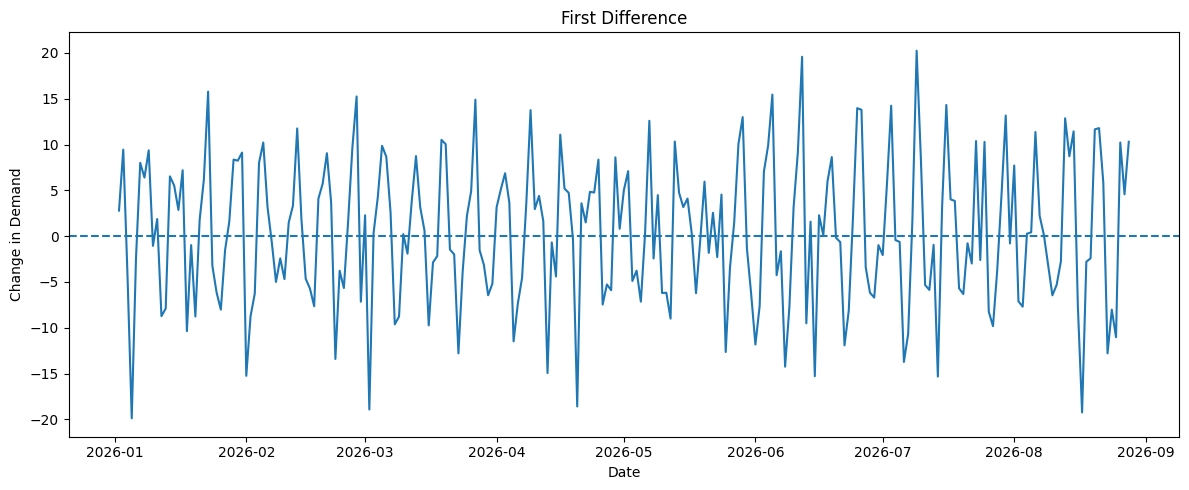

In [7]:
df["first_difference"]=df["demand"].diff()

plt.figure(figsize=(12,5))
plt.plot(df["date"],df["first_difference"])
plt.axhline(0,linestyle="--")
plt.xlabel("Date")
plt.ylabel("Change in Demand")
plt.title("First Difference")
plt.tight_layout()
plt.show()


## 6. Seasonal differencing

If a series has weekly seasonality, compare each observation with the value 7 days earlier:

`seasonal_difference_t = value_t - value_(t-7)`


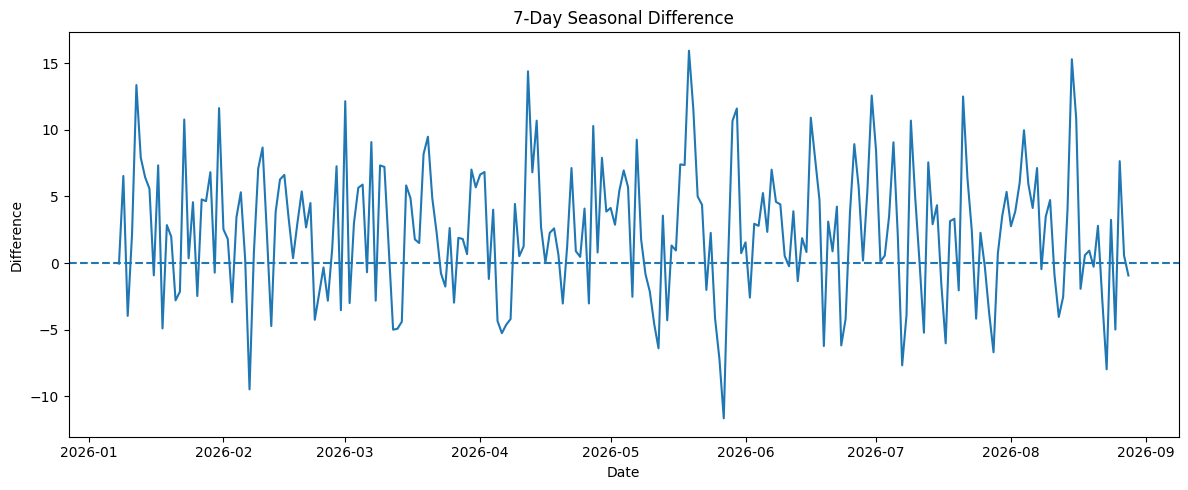

In [8]:
df["seasonal_difference"]=df["demand"].diff(7)

plt.figure(figsize=(12,5))
plt.plot(df["date"],df["seasonal_difference"])
plt.axhline(0,linestyle="--")
plt.xlabel("Date")
plt.ylabel("Difference")
plt.title("7-Day Seasonal Difference")
plt.tight_layout()
plt.show()


## 7. Augmented Dickey-Fuller test

A popular statistical test for stationarity is:

**ADF — Augmented Dickey-Fuller**

Its null hypothesis is approximately that the series has a unit root and is non-stationary.

A small p-value gives evidence against that null.

A commonly used threshold is `p < 0.05`, but it should not be interpreted mechanically.


In [9]:
# Install once if needed:
# pip install statsmodels

from statsmodels.tsa.stattools import adfuller


In [10]:
raw_result=adfuller(df["demand"].dropna())

print("RAW SERIES")
print("ADF Statistic:",round(raw_result[0],4))
print("p-value:",round(raw_result[1],4))


RAW SERIES
ADF Statistic: -0.4883
p-value: 0.8943


/tmp/ipykernel_633/221446799.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  raw_result=adfuller(df["demand"].dropna())


In [11]:
diff_result=adfuller(df["first_difference"].dropna())

print("FIRST DIFFERENCE")
print("ADF Statistic:",round(diff_result[0],4))
print("p-value:",round(diff_result[1],4))


FIRST DIFFERENCE
ADF Statistic: -8.2494
p-value: 0.0


/tmp/ipykernel_633/3763081641.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  diff_result=adfuller(df["first_difference"].dropna())


## 8. Why this matters

Suppose a model learns:

`Average demand ≈ 110`

but months later the normal level becomes:

`170`

The environment has changed.

A model that assumes stable behavior may become unreliable.

Differencing or other transformations can sometimes make the forecasting problem more stable.


## Enterprise intuition

Stationarity matters in:
- demand forecasting
- infrastructure forecasting
- finance
- sensor monitoring
- staffing and workload forecasting

The practical question is:

> Are the relationships learned from the past still valid in the future?


## Important caution

Not every forecasting model requires perfectly stationary data.

Tree-based and deep-learning models may work directly with trend and seasonal features.

But stationarity remains a foundational idea because it forces us to inspect whether the data-generating process itself is changing.


## What does this teach?

- Stationarity means statistical behavior is relatively stable over time.
- Trend is a common cause of non-stationarity.
- Seasonality can also create repeating structure.
- Rolling statistics help visualize changing behavior.
- First differencing can reduce trend.
- Seasonal differencing can reduce recurring seasonal effects.
- ADF is a popular statistical test.
- Statistical tests should be combined with visual and domain analysis.

> **Forecasting becomes difficult when the rules keep changing. Stationarity asks whether the past and future come from roughly the same statistical process.**


## References

- https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html
- https://otexts.com/fpp3/stationarity.html
- https://pandas.pydata.org/docs/user_guide/timeseries.html
